# ConvNeXt-Tiny: ResNet-inspired training pipeline

Run in a fresh Kaggle GPU session with Internet enabled. The backbone stays
`convnext_tiny.fb_in1k`, `pretrained=True`, with a head sized from `LABEL_COLS`.
Only ImageNet-1k initialization and the provided competition data are used.

This is multilabel classification: BCEWithLogitsLoss and independent sigmoid outputs.
The existing grouped folds and validation metric definitions are preserved.
Validation accuracy means exact match of all labels in a photo.

Inspired by `ResNet.ipynb`: resize the full image to 224 x 224, use mild flip/translation/
brightness/contrast augmentation, and weight positive labels by sqrt(negatives / positives)
computed on the training fold only. Keep AdamW and train for up to 15 epochs with cosine
decay and early stopping after 5 epochs without a higher validation macro F1 at 0.5.

After selecting the best checkpoint at threshold 0.5, tune one threshold per class on
the held-out fold. Save them inside `best.pt` and `thresholds.json`; both inference
notebooks use those thresholds and the recorded preprocessing. Tuned validation F1 is
an in-sample calibration result, not an independent score; compare it with the fixed-0.5
result and the Kaggle score. No mutually exclusive Moris/Motya rule is applied.

Restart the kernel and Run All to train this new experiment from ImageNet-1k weights.
The new `_resnet_pipeline` directory preserves the previous `_full` run.
If `folds.csv` is absent, the unchanged `Validation.ipynb` recipe creates and caches it.
Test inference is optional via `RUN_TEST_INFERENCE`.

### Environment setup (only if packages are missing)

Run the optional install cell separately, then restart the kernel before imports.
Do not install packages inside the import cell. The previous DataLoader cleanup issue is addressed with plain `tqdm` and `NUM_WORKERS = 0`.

To create a submission from saved weights without training, open **cnn_2_inference.ipynb**. Notebook outputs do not contain the trained weights; keep/download `best.pt` from Kaggle Output before ending the session.


In [1]:
# Run separately only if packages are missing; restart the kernel afterwards.
# %pip install -q timm wandb "albumentations>=2,<3"

In [2]:
import json
import os
import random
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from tqdm import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

print('torch:', torch.__version__, '| timm:', timm.__version__)

torch: 2.11.0+cu128 | timm: 1.0.29


## 1. Configuration

New experiment on the existing fold 0: at most 15 epochs at 224 px, batch size 32,
AdamW LR `1e-4`, cosine decay to `1e-6`, and F1 early-stopping patience 5.
Use batch size 16 if GPU memory is insufficient. W&B logs the baseline metrics,
per-class F1, and a separate final threshold-calibration result.

In [3]:
SEED = 21
DATA_DIR = Path('/kaggle/input/competitions/cats-and-dogs')
FOLDS_PATH = None  # auto-find folds.csv; create it if missing, or set an explicit path
LABEL_COLS = ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
FOLD = 0
MODEL_NAME = 'convnext_tiny.fb_in1k'
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
EARLY_STOPPING_PATIENCE = 5
LR = 1e-4
MIN_LR = 1e-6
WEIGHT_DECAY = 1e-2
THRESHOLD = 0.5
NUM_WORKERS = 0  # avoid notebook DataLoader multiprocessing cleanup errors
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
OUTPUT_DIR = Path('/kaggle/working') / f'convnext_tiny_fb_in1k_fold{FOLD}_resnet_pipeline'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = OUTPUT_DIR / 'best.pt'
FOLDS_CACHE_PATH = OUTPUT_DIR.parent / 'folds.csv'

USE_WANDB = True
WANDB_PROJECT = 'cats-and-dogs'
WANDB_ENTITY = 'yrachynska-kyiv-school-of-economics'  # shared team project
WANDB_RUN_NAME = f'convnext-tiny-fb-in1k-fold{FOLD}-resnet-pipeline'
WANDB_MODE = 'online'  # 'online', 'offline', or 'disabled'
WANDB_LOG_EVERY = 20  # optimizer steps between batch-loss logs
RUN_TEST_INFERENCE = False

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
assert EPOCHS > 0 and BATCH_SIZE > 0 and 0 < THRESHOLD < 1
assert EARLY_STOPPING_PATIENCE > 0 and 0 <= MIN_LR <= LR
print('device:', DEVICE, '| output:', OUTPUT_DIR)
if DEVICE.type == 'cuda':
    print(torch.cuda.get_device_name(0))
else:
    print('CPU mode: useful for debugging; enable a GPU for training.')

device: cuda | output: /kaggle/working/convnext_tiny_fb_in1k_fold0_resnet_pipeline
Tesla T4


### W&B setup (Weights & Biases)

1. Get an API key from [W&B settings](https://wandb.ai/authorize).
2. In Kaggle, open **Add-ons → Secrets**, add a secret named **WANDB_API_KEY**,
   and grant this notebook access. Keep Internet enabled for live charts.
3. Set `WANDB_PROJECT` and, if needed, `WANDB_ENTITY` above. Each training-cell execution
   creates a run; the training cell prints its dashboard URL.

After the baseline works, set `USE_WANDB = True`. The dashboard shows batch loss,
epoch train/validation BCE, exact-match validation accuracy, macro F1, macro ROC-AUC,
and learning rate, plus the run configuration.
The summary records the best epoch by macro F1 and its corresponding metrics.
The run closes automatically when training ends or raises an error.

Set `USE_WANDB = False` to train without W&B. Set `WANDB_MODE = 'offline'` to log
locally without a key; live charts require an online run. Download the offline run
folder from `OUTPUT_DIR / 'wandb'` and run `wandb sync <offline-run-folder>` later.
These settings affect logging; downloading pretrained weights still needs Internet.

References: [Kaggle Secrets](https://github.com/Kaggle/kaggle-cli/blob/main/docs/kernels.md#using-secrets-in-kernels),
[W&B run logging](https://docs.wandb.ai/ref/python/experiments/run/).

W&B comparison: new runs use the shared team `yrachynska-kyiv-school-of-economics` / `cats-and-dogs`. They also log `val_f1`, `val_loss`, `train_loss_epoch` and `lr` against `epoch`, alongside the original `epoch_metrics/*` keys. For existing runs, select both `val_f1` and `epoch_metrics/val_f1` in a workspace line plot with X = `epoch`; old history is not rewritten. F1 aliases use the fixed 0.5 threshold, not the fitted calibration score. ResNet validation BCE is weighted and ConvNeXt validation BCE is unweighted, so their loss magnitudes are not directly comparable.

In [4]:
wandb_run = None
train_step = 0

def start_wandb_run(config):
    if not USE_WANDB or WANDB_MODE == 'disabled':
        return nullcontext(None)
    if WANDB_MODE not in {'online', 'offline'}:
        raise ValueError('WANDB_MODE must be online, offline, or disabled.')
    if WANDB_LOG_EVERY < 1:
        raise ValueError('WANDB_LOG_EVERY must be positive.')
    try:
        import wandb
    except ImportError:
        raise ImportError('Install wandb with %pip install -q wandb, or set USE_WANDB = False.') from None

    if WANDB_MODE == 'online' and not os.environ.get('WANDB_API_KEY'):
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret('WANDB_API_KEY')
        except Exception:
            raise RuntimeError(
                'Add the WANDB_API_KEY Kaggle Secret and grant notebook access, '
                'or set the WANDB_API_KEY environment variable. '
                'For local logging use WANDB_MODE = "offline".'
            ) from None
        if not api_key:
            raise RuntimeError('WANDB_API_KEY is empty. Check the Kaggle Secret.')
        os.environ['WANDB_API_KEY'] = api_key  # never print or put the key in run config

    return wandb.init(
        project=WANDB_PROJECT, entity=WANDB_ENTITY, name=WANDB_RUN_NAME,
        mode=WANDB_MODE, config=config, dir=str(OUTPUT_DIR), save_code=False,
    )

## 2. Load or create grouped folds

Prefer `folds.csv` from `Validation.ipynb`. If none is available, reproduce its recipe:
ResNet18 embeddings, cosine similarity 0.95, connected components, rare-pet-first strata,
and `StratifiedGroupKFold(5, seed=21)`. The first run also downloads the ImageNet-pretrained
ResNet18 weights and extracts train-image embeddings; later runs reuse the saved CSV.
Keep the exported CSV to reuse the exact split across sessions and machines.

The checks below verify image IDs, labels, complete fold assignments and group separation.
There is no random-split fallback. Original competition labels are preserved.

In [5]:
def create_grouped_folds(frame):
    # Same grouping and stratification recipe as Validation.ipynb.
    from concurrent.futures import ThreadPoolExecutor
    from sklearn.neighbors import NearestNeighbors
    from scipy.sparse.csgraph import connected_components
    from sklearn.model_selection import StratifiedGroupKFold

    grouped = frame[['image_id', *LABEL_COLS]].copy().reset_index(drop=True)
    assert len(grouped) >= 5, 'At least five images are required for five folds.'
    paths = [DATA_DIR / 'train' / f'{image_id}.jpg' for image_id in grouped.image_id]
    print(f'Creating folds: loading ResNet18 on {DEVICE} for {len(grouped)} images...', flush=True)
    feature_model = timm.create_model(
        'resnet18.a1_in1k', pretrained=True, num_classes=0,
    ).eval().to(DEVICE)
    transform = timm.data.create_transform(
        **timm.data.resolve_data_config({}, model=feature_model),
    )

    def load_image(image_path):
        with Image.open(image_path) as image:
            image.draft('RGB', (320, 320))
            return transform(image.convert('RGB'))

    feature_batches = []
    print('No folds.csv found: creating grouped folds with the Validation.ipynb recipe.')
    try:
        with ThreadPoolExecutor(max_workers=min(4, os.cpu_count() or 1)) as pool, torch.inference_mode():
            for start in tqdm(range(0, len(paths), 128), desc='fold embeddings'):
                images = torch.stack(list(pool.map(load_image, paths[start:start + 128])))
                feature_batches.append(feature_model(images.to(DEVICE)).cpu())
        features = torch.cat(feature_batches).numpy()
    finally:
        del feature_model
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    assert np.isfinite(features).all(), 'Non-finite grouping embeddings.'

    print('Embeddings ready. Finding similar-photo groups...', flush=True)
    knn = NearestNeighbors(radius=1 - 0.95, metric='cosine', algorithm='brute').fit(features)
    grouped['cluster'] = connected_components(knn.radius_neighbors_graph(features), directed=False)[1]
    assert grouped.cluster.nunique() >= 5, 'Fewer than five distinct image groups.'
    pet_cols = ['Moris', 'Motya', 'Biatrix']
    pets_rarest_first = sorted(pet_cols, key=lambda label: grouped[label].sum())

    def stratum(row):
        for label in pets_rarest_first:
            if row[label] == 1:
                return label
        return ('Cat' * int(row.Cat) + 'Dog' * int(row.Dog)) or 'None'

    strata = grouped.apply(stratum, axis=1)
    grouped['fold'] = -1
    print('Assigning the existing five grouped folds...', flush=True)
    splitter = StratifiedGroupKFold(5, shuffle=True, random_state=21)
    for fold, (_, val_indices) in enumerate(splitter.split(grouped, strata, groups=grouped.cluster)):
        grouped.loc[val_indices, 'fold'] = fold
    assert set(grouped.fold.unique()) == set(range(5))
    assert grouped.groupby('cluster').fold.nunique().eq(1).all()
    FOLDS_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    grouped.to_csv(FOLDS_CACHE_PATH, index=False)
    print('Saved grouped folds:', FOLDS_CACHE_PATH, '| distinct photos:', grouped.cluster.nunique())
    return FOLDS_CACHE_PATH

In [6]:
# Locate the mounted competition dataset; leave the existing split/loaders unchanged.
KAGGLE_INPUT_DIR = Path('/kaggle/input')
if not ((DATA_DIR / 'train.csv').is_file() and (DATA_DIR / 'test.csv').is_file()):
    data_candidates = []
    for csv_path in sorted(KAGGLE_INPUT_DIR.rglob('train.csv')):
        root = csv_path.parent
        if not ((root / 'test.csv').is_file() and (root / 'train').is_dir() and (root / 'test').is_dir()):
            continue
        try:
            columns = pd.read_csv(csv_path, nrows=0).columns
        except (OSError, ValueError):
            continue
        if {'image_id', *LABEL_COLS}.issubset(columns):
            data_candidates.append(root)
    if len(data_candidates) == 1:
        DATA_DIR = data_candidates[0]
    elif len(data_candidates) > 1:
        raise ValueError(f'Multiple matching datasets found. Set DATA_DIR explicitly to one of: {data_candidates}')
    else:
        mounted = sorted(p.name for p in KAGGLE_INPUT_DIR.iterdir()) if KAGGLE_INPUT_DIR.is_dir() else []
        raise FileNotFoundError(
            f'Competition CSVs not found at {DATA_DIR} or under {KAGGLE_INPUT_DIR}. '
            'In Kaggle, attach the Cats and Dogs competition data using Add Input/Add Data, '
            'or set DATA_DIR to your actual dataset directory. '
            f'Currently mounted inputs: {mounted}'
        )
print('Using dataset:', DATA_DIR)

Using dataset: /kaggle/input/competitions/cats-and-dogs


In [7]:
print('Reading train.csv and test.csv...', flush=True)
train = pd.read_csv(DATA_DIR / 'train.csv', dtype={'image_id': str})
test = pd.read_csv(DATA_DIR / 'test.csv', dtype={'image_id': str})
assert train.image_id.notna().all() and train.image_id.is_unique
assert test.image_id.notna().all() and test.image_id.is_unique
assert train[LABEL_COLS].isin([0, 1]).all().all(), 'Expected binary multilabel targets.'

if FOLDS_PATH is None:
    local_candidates = [Path('folds.csv'), FOLDS_CACHE_PATH]
    candidates = sorted({p.resolve() for p in local_candidates if p.is_file()})
    if not candidates:
        print('Searching attached inputs for folds.csv...', flush=True)
        candidates = []
        image_dirs = {DATA_DIR / 'train', DATA_DIR / 'test'}
        for directory, subdirs, files in os.walk('/kaggle/input'):
            # Skip the image directories: exported folds.csv belongs outside them.
            subdirs[:] = [name for name in subdirs if Path(directory) / name not in image_dirs]
            if 'folds.csv' in files:
                candidates.append(Path(directory) / 'folds.csv')
        candidates = sorted(candidates)
    if not candidates:
        candidates = [create_grouped_folds(train)]
    if len(candidates) != 1:
        raise ValueError(f'Multiple folds.csv files found; set FOLDS_PATH explicitly: {candidates}')
    FOLDS_PATH = candidates[0]
FOLDS_PATH = Path(FOLDS_PATH)
print('Loading folds:', FOLDS_PATH, flush=True)
folds = pd.read_csv(FOLDS_PATH, dtype={'image_id': str})
assert folds.image_id.notna().all() and folds.image_id.is_unique
assert {'cluster', 'fold', *LABEL_COLS}.issubset(folds.columns)
assert set(folds.image_id) == set(train.image_id), 'folds.csv does not match train.csv.'
aligned = folds.set_index('image_id').loc[train.image_id]
assert np.array_equal(train[LABEL_COLS].to_numpy(), aligned[LABEL_COLS].to_numpy()), 'Stale labels in folds.csv.'

train = train.merge(folds[['image_id', 'cluster', 'fold']], on='image_id', validate='one_to_one', sort=False)
assert train[['cluster', 'fold']].notna().all().all()
assert set(train.fold.unique()) == set(range(5)), 'Expected folds 0–4 from Validation.ipynb.'
assert train.groupby('cluster').fold.nunique().eq(1).all(), 'A duplicate group crosses folds.'
train['path'] = train.image_id.map(lambda image_id: str(DATA_DIR / 'train' / f'{image_id}.jpg'))
test['path'] = test.image_id.map(lambda image_id: str(DATA_DIR / 'test' / f'{image_id}.jpg'))
for split_name, frame in [('train', train), ('test', test)]:
    missing = [p for p in tqdm(frame.path, desc=f'Checking {split_name} files', unit='image') if not Path(p).is_file()]
    assert not missing, f'Missing images, e.g. {missing[:3]}'

train_df = train.loc[train.fold != FOLD].reset_index(drop=True)
val_df = train.loc[train.fold == FOLD].reset_index(drop=True)
assert len(train_df) > 0 and len(val_df) > 0
assert set(train_df.cluster).isdisjoint(val_df.cluster)
print('folds:', FOLDS_PATH)
print('train:', len(train_df), '| validation:', len(val_df), '| test:', len(test))
display(pd.DataFrame({'train positives': train_df[LABEL_COLS].sum(), 'val positives': val_df[LABEL_COLS].sum()}))

# Fold generation must not change the RNG state used to initialize/train ConvNeXt.
seed_everything(SEED)

Reading train.csv and test.csv...
Searching attached inputs for folds.csv...
Creating folds: loading ResNet18 on cuda for 12260 images...


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

No folds.csv found: creating grouped folds with the Validation.ipynb recipe.


fold embeddings: 100%|██████████| 96/96 [01:23<00:00,  1.15it/s]

Embeddings ready. Finding similar-photo groups...


Assigning the existing five grouped folds...
Saved grouped folds: /kaggle/working/folds.csv | distinct photos: 12186
Loading folds: /kaggle/working/folds.csv


Checking test files: 100%|██████████| 18673/18673 [00:51<00:00, 365.89image/s]

folds: /kaggle/working/folds.csv
train: 9812 | validation: 2448 | test: 18673


,train positives,val positives
Cat,4071,1006
Dog,4043,982
Moris,42,14
Motya,35,7
Biatrix,32,9


## 3. Imports / model

Create the ImageNet-1k pretrained ConvNeXt-Tiny in PyTorch/timm. Determine the
output count from `LABEL_COLS`, the existing dataset metadata. `num_classes` replaces
the original classifier; move the model to CUDA when available.

In [8]:
import torch
from torch import nn
import timm

num_classes = len(LABEL_COLS)
model = timm.create_model(
    MODEL_NAME, pretrained=True, num_classes=num_classes,
).to(DEVICE)
print('model:', MODEL_NAME, '| classes:', num_classes, '| device:', DEVICE)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model: convnext_tiny.fb_in1k | classes: 5 | device: cuda


### Full-frame preprocessing / dataloaders

Use the same augmentation recipe as the ResNet notebook: resize, horizontal flip,
translation up to 10%, and mild brightness/contrast changes. Validation/test only
resize and normalize with the ConvNeXt model's mean/std. Resize preserves the full
field of view, but stretches the rectangular image to a square.

Rebuild loaders here so rerunning this cell cannot reuse old crop-based transforms.
The train/validation rows, labels, fold assignments and validation function stay unchanged.

In [9]:
data_config = timm.data.resolve_data_config({}, model=model)
data_config['input_size'] = (3, IMAGE_SIZE, IMAGE_SIZE)
preprocessing = {
    'name': 'albumentations_resize_v1', 'image_size': IMAGE_SIZE,
    'mean': list(data_config['mean']), 'std': list(data_config['std']),
    'interpolation': 1,  # OpenCV INTER_LINEAR, as in the ResNet notebook
}
train_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE, interpolation=preprocessing['interpolation']),
    A.HorizontalFlip(p=0.5),
    A.Affine(translate_percent=(-0.1, 0.1), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=preprocessing['mean'], std=preprocessing['std']),
    ToTensorV2(),
])
if hasattr(train_transform, 'set_random_seed'):
    train_transform.set_random_seed(SEED)
eval_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE, interpolation=preprocessing['interpolation']),
    A.Normalize(mean=preprocessing['mean'], std=preprocessing['std']),
    ToTensorV2(),
])

class PetDataset(Dataset):
    def __init__(self, frame, transform, with_labels=True):
        self.paths = frame.path.tolist()
        self.targets = frame[LABEL_COLS].to_numpy(dtype=np.float32) if with_labels else None
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            pixels = np.array(image.convert('RGB'))
        x = self.transform(image=pixels)['image']
        if self.targets is None:
            return x
        return x, torch.from_numpy(self.targets[index])

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(frame, training=False, with_labels=True):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        PetDataset(frame, train_transform if training else eval_transform, with_labels),
        batch_size=BATCH_SIZE, shuffle=training, num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == 'cuda', drop_last=False,
        worker_init_fn=seed_worker, generator=generator,
    )

train_loader = make_loader(train_df, training=True)
val_loader = make_loader(val_df)
test_loader = make_loader(test, with_labels=False)
print('Rebuilt loaders:', len(train_loader.dataset), 'train,', len(val_loader.dataset), 'validation')

Rebuilt loaders: 9812 train, 2448 validation


## 4. Training setup

Like the ResNet pipeline, weight positives by `sqrt(negatives / positives)` using only
training-fold counts. This increases the contribution of the rare pet labels.
Keep unweighted validation BCE and the existing validation function for comparison
with the previous run. AdamW, epoch-wise cosine decay and CUDA mixed precision remain.

The threshold helper is used only after training. On ties, prefer the threshold closest
to 0.5; if a validation class lacks positives or negatives, keep 0.5 for that class.

In [10]:
positive_counts = train_df[LABEL_COLS].sum().to_numpy(dtype=np.float32)
negative_counts = len(train_df) - positive_counts
assert (positive_counts > 0).all() and (negative_counts > 0).all(), 'Each training label needs both outcomes.'
pos_weight = torch.as_tensor(np.sqrt(negative_counts / positive_counts), device=DEVICE)
train_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
display(pd.DataFrame({'train positives': positive_counts, 'positive weight': pos_weight.cpu().tolist()}, index=LABEL_COLS))
val_criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MIN_LR)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

def metric_report(targets, probabilities, threshold=THRESHOLD):
    predictions = (probabilities >= threshold).astype(np.int32)
    rows = []
    for j, label in enumerate(LABEL_COLS):
        y = targets[:, j]
        auc = roc_auc_score(y, probabilities[:, j]) if np.unique(y).size == 2 else np.nan
        rows.append({
            'label': label,
            'positives': int(y.sum()),
            'predicted positives': int(predictions[:, j].sum()),
            'f1': f1_score(y, predictions[:, j], zero_division=0),
            'precision': precision_score(y, predictions[:, j], zero_division=0),
            'recall': recall_score(y, predictions[:, j], zero_division=0),
            'roc_auc': auc,
        })
    table = pd.DataFrame(rows).set_index('label')
    valid_auc = table.roc_auc.dropna()
    metrics = {
        'macro_f1': float(f1_score(targets, predictions, average='macro', zero_division=0)),
        'macro_roc_auc': float(valid_auc.mean()) if len(valid_auc) else float('nan'),
    }
    return metrics, table

def tune_thresholds(targets, probabilities):
    thresholds = np.full(len(LABEL_COLS), THRESHOLD, dtype=np.float64)
    candidates = np.round(np.linspace(0.05, 0.95, 91), 2)
    for j, label in enumerate(LABEL_COLS):
        if np.unique(targets[:, j]).size < 2:
            print(f'{label}: keeping {THRESHOLD}; validation does not contain both outcomes.')
            continue
        scores = np.array([
            f1_score(targets[:, j], probabilities[:, j] >= t, zero_division=0)
            for t in candidates
        ])
        tied = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=1e-12))
        best = tied[np.argmin(np.abs(candidates[tied] - THRESHOLD))]
        thresholds[j] = candidates[best]
    return thresholds

,train positives,positive weight
Cat,4071.0,1.187526
Dog,4043.0,1.194534
Moris,42.0,15.251854
Motya,35.0,16.713552
Biatrix,32.0,17.482134


In [11]:
def train_one_epoch():
    global train_step
    model.train()
    total_loss = 0.0
    seen = 0
    progress = tqdm(train_loader, desc='train', leave=False)
    for batch_index, (images, targets) in enumerate(progress, start=1):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = train_criterion(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'Non-finite training loss: {loss.item()}')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(images)
        seen += len(images)
        progress.set_postfix(loss=f'{total_loss / seen:.4f}')
        train_step += 1
        if wandb_run is not None and (train_step % WANDB_LOG_EVERY == 0 or batch_index == len(train_loader)):
            wandb_run.log({
                'train_step': train_step, 'batch/loss': loss.item(),
                'batch/running_loss': total_loss / seen,
            })
    return total_loss / seen

@torch.inference_mode()
def validate():
    model.eval()
    total_loss = 0.0
    all_targets, all_probabilities = [], []
    for images, targets in tqdm(val_loader, desc='validation', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
        loss = val_criterion(logits.float(), targets)
        total_loss += loss.item() * len(images)
        all_targets.append(targets.cpu().numpy())
        all_probabilities.append(logits.float().sigmoid().cpu().numpy())
    targets = np.concatenate(all_targets)
    probabilities = np.concatenate(all_probabilities)
    assert np.isfinite(probabilities).all(), 'Non-finite validation probabilities.'
    metrics, table = metric_report(targets, probabilities)
    metrics['val_loss'] = total_loss / len(val_df)
    assert np.isfinite(metrics['val_loss']), 'Non-finite validation loss.'
    return metrics, table, probabilities

## 5. Full training loop

Check one validation batch, then train up to `EPOCHS`. Log losses, exact-match accuracy,
macro F1, actual learning rate and epoch duration. Stop after 5 consecutive epochs
without a higher macro F1. A lower validation loss breaks ties for checkpoint selection
but does not reset the F1 patience counter. The best weights and history are saved.

In [12]:
model.eval()
with torch.inference_mode():
    images, targets = next(iter(val_loader))
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        logits = model(images.to(DEVICE))
    assert logits.shape == targets.shape == (len(images), len(LABEL_COLS))
    assert torch.isfinite(logits).all()
print('smoke check passed:', tuple(images.shape), '->', tuple(logits.shape))
del images, targets, logits

smoke check passed: (32, 3, 224, 224) -> (32, 5)


In [13]:
from time import perf_counter

run_config = {
    'model_name': MODEL_NAME, 'label_cols': LABEL_COLS, 'num_classes': num_classes,
    'seed': SEED, 'fold': FOLD, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'image_size': IMAGE_SIZE, 'lr': LR, 'min_lr': MIN_LR, 'weight_decay': WEIGHT_DECAY,
    'scheduler': 'CosineAnnealingLR', 'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'threshold': THRESHOLD, 'selection_metric': 'macro_f1', 'data_config': data_config,
    'folds_path': str(FOLDS_PATH),
    'preprocessing': preprocessing, 'pos_weight': pos_weight.cpu().tolist(),
    'optimizer': 'AdamW', 'train_loss': 'BCEWithLogitsLoss_sqrt_pos_weight',
    'val_loss': 'BCEWithLogitsLoss_unweighted',
    'augmentation': {'hflip_p': 0.5, 'translate_percent': [-0.1, 0.1],
                     'affine_p': 0.5, 'brightness_limit': 0.1, 'contrast_limit': 0.1,
                     'brightness_contrast_p': 0.5},
    'albumentations_version': A.__version__,
    'threshold_calibration': 'per_class_grid_0.05_0.95_on_best_checkpoint_validation',
}
(OUTPUT_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))
history = []
best_f1, best_loss = -1.0, float('inf')
epochs_without_improvement = 0
train_step = 0
val_targets = val_df[LABEL_COLS].to_numpy(dtype=np.int32)

try:
    with start_wandb_run(run_config) as wandb_run:
        if wandb_run is not None:
            wandb_run.define_metric('train_step')
            wandb_run.define_metric('batch/*', step_metric='train_step')
            wandb_run.define_metric('epoch')
            wandb_run.define_metric('epoch_metrics/*', step_metric='epoch')
            wandb_run.define_metric('epoch_metrics/val_f1', step_metric='epoch', summary='max')
            # Shared names match the ResNet runs; keep scalar last-value summaries.
            for metric in ('val_f1', 'val_loss', 'train_loss_epoch', 'lr'):
                wandb_run.define_metric(metric, step_metric='epoch')
            print('W&B:', wandb_run.url if WANDB_MODE == 'online' else wandb_run.dir)

        for epoch in range(1, EPOCHS + 1):
            epoch_start = perf_counter()
            epoch_lr = optimizer.param_groups[0]['lr']
            train_loss = train_one_epoch()
            metrics, epoch_per_label, val_probabilities = validate()
            val_predictions = (val_probabilities >= THRESHOLD).astype(np.int32)
            assert val_predictions.shape == val_targets.shape
            metrics['val_accuracy'] = float((val_predictions == val_targets).all(axis=1).mean())
            f1_improved = metrics['macro_f1'] > best_f1
            epochs_without_improvement = 0 if f1_improved else epochs_without_improvement + 1
            row = {'epoch': epoch, 'train_loss': train_loss, **metrics, 'lr': epoch_lr,
                   'epoch_seconds': perf_counter() - epoch_start,
                   'epochs_without_improvement': epochs_without_improvement}
            history.append(row)
            pd.DataFrame(history).to_csv(OUTPUT_DIR / 'history.csv', index=False)
            print(f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f} | "
                  f"val loss {metrics['val_loss']:.4f} | val accuracy {metrics['val_accuracy']:.2%} | "
                  f"macro F1 {metrics['macro_f1']:.4f} | LR {epoch_lr:.2e} | "
                  f"{row['epoch_seconds']:.0f}s | patience {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}")

            if f1_improved or (metrics['macro_f1'] == best_f1 and metrics['val_loss'] < best_loss):
                best_f1, best_loss = metrics['macro_f1'], metrics['val_loss']
                torch.save({'model': model.state_dict(), 'epoch': epoch,
                            'metrics': metrics, 'config': run_config}, BEST_PATH)
                print('  Saved best checkpoint')
                if wandb_run is not None:
                    wandb_run.summary.update({'best/epoch': epoch, 'best/macro_f1': best_f1,
                                              'best/val_accuracy': metrics['val_accuracy']})
            if wandb_run is not None:
                log = {'epoch': epoch, 'epoch_metrics/val_f1': metrics['macro_f1']}
                log.update({f'epoch_metrics/{key}': value for key, value in row.items()
                            if key != 'epoch' and np.isfinite(value)})
                log.update({f'epoch_metrics/f1_{label}': float(epoch_per_label.loc[label, 'f1'])
                            for label in LABEL_COLS})
                # Compatibility aliases for side-by-side ResNet/ConvNeXt panels.
                log.update({'val_f1': metrics['macro_f1'], 'val_loss': metrics['val_loss'],
                             'train_loss_epoch': train_loss, 'lr': epoch_lr})
                wandb_run.log(log)
                wandb_run.summary['completed_epochs'] = epoch

            scheduler.step()
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f'Early stopping: no higher macro F1 for {EARLY_STOPPING_PATIENCE} epochs.')
                break
        # Calibrate only the selected checkpoint, using held-out labels (never test labels).
        checkpoint = torch.load(BEST_PATH, map_location='cpu', weights_only=True)
        model.load_state_dict(checkpoint['model'])
        baseline_metrics, _, val_probabilities = validate()
        thresholds = tune_thresholds(val_targets, val_probabilities)
        calibrated_metrics, calibrated_per_label = metric_report(val_targets, val_probabilities, thresholds)
        calibrated_metrics['val_accuracy'] = float(((val_probabilities >= thresholds) == val_targets).all(axis=1).mean())
        threshold_map = dict(zip(LABEL_COLS, thresholds.tolist()))
        checkpoint['thresholds'] = thresholds.tolist()  # same order as config['label_cols']
        checkpoint['calibration_metrics'] = calibrated_metrics
        torch.save(checkpoint, BEST_PATH)
        calibration = {
            'thresholds': threshold_map, 'source': 'best_checkpoint_validation_fold',
            'fold': FOLD, 'epoch': checkpoint['epoch'],
            'macro_f1_at_0_5': baseline_metrics['macro_f1'],
            'macro_f1_tuned': calibrated_metrics['macro_f1'],
        }
        (OUTPUT_DIR / 'thresholds.json').write_text(json.dumps(calibration, indent=2))
        print('Saved validation-fitted thresholds:', threshold_map)
        print('Validation F1 at 0.5:', baseline_metrics['macro_f1'],
              '| tuned (same calibration fold):', calibrated_metrics['macro_f1'])
        if wandb_run is not None:
            wandb_run.log({
                'calibration/val_f1': calibrated_metrics['macro_f1'],
                'calibration/val_accuracy': calibrated_metrics['val_accuracy'],
                **{f'calibration/threshold_{label}': threshold_map[label] for label in LABEL_COLS},
                **{f'calibration/f1_{label}': float(calibrated_per_label.loc[label, 'f1']) for label in LABEL_COLS},
            })
            wandb_run.summary.update({'calibration/macro_f1_at_0_5': baseline_metrics['macro_f1'],
                                      'calibration/macro_f1_tuned': calibrated_metrics['macro_f1'],
                                      'calibration/thresholds': threshold_map})
finally:
    wandb_run = None

display(pd.DataFrame(history))
print('Best checkpoint:', BEST_PATH, '| macro F1:', best_f1)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: mkovalenko (mkovalenko-kyiv-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B: https://wandb.ai/mkovalenko-kyiv-school-of-economics/cats-and-dogs/runs/ehv5ffr6


Epoch 1/15 | train loss 0.1163 | val loss 0.0229 | val accuracy 97.71% | macro F1 0.7498 | LR 1.00e-04 | 123s | patience 0/5
  Saved best checkpoint


Epoch 2/15 | train loss 0.0230 | val loss 0.0147 | val accuracy 98.37% | macro F1 0.8847 | LR 9.89e-05 | 100s | patience 0/5
  Saved best checkpoint


Epoch 3/15 | train loss 0.0097 | val loss 0.0161 | val accuracy 97.92% | macro F1 0.9268 | LR 9.57e-05 | 101s | patience 0/5
  Saved best checkpoint


...

Epoch 15/15 | train loss 0.0002 | val loss 0.0119 | val accuracy 99.31% | macro F1 0.9724 | LR 2.08e-06 | 98s | patience 0/5
  Saved best checkpoint


Saved validation-fitted thresholds: {'Cat': 0.5, 'Dog': 0.5, 'Moris': 0.5, 'Motya': 0.5, 'Biatrix': 0.5}
Validation F1 at 0.5: 0.972387075747738 | tuned (same calibration fold): 0.972387075747738


batch/loss,█▄▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
batch/running_loss,█▇▇▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
calibration/f1_Biatrix,▁
calibration/f1_Cat,▁
calibration/f1_Dog,▁
calibration/f1_Moris,▁
calibration/f1_Motya,▁
calibration/threshold_Biatrix,▁
calibration/threshold_Cat,▁
calibration/threshold_Dog,▁
+20,...


,epoch,train_loss,macro_f1,macro_roc_auc,val_loss,val_accuracy,lr,epoch_seconds,epochs_without_improvement
0,1,0.116309,0.749842,0.998987,0.022941,0.977124,0.000100,122.926829,0
1,2,0.023003,0.884678,0.999651,0.014697,0.983660,0.000099,100.172463,0
2,3,0.009683,0.926846,0.999744,0.016067,0.979167,0.000096,100.647142,0
3,4,0.003388,0.959917,0.999796,0.010962,0.989788,0.000091,97.968504,0
4,5,0.002963,0.961132,0.999579,0.013051,0.988971,0.000084,97.467095,0
5,6,0.001331,0.972090,0.999780,0.013332,0.991830,0.000075,99.442149,0
6,7,0.000818,0.971386,0.999666,0.010942,0.989379,0.000066,97.454150,1
7,8,0.000453,0.971683,0.999679,0.011525,0.991013,0.000056,97.526471,2
8,9,0.000351,0.971686,0.999670,0.012167,0.991013,0.000045,96.755399,3
9,10,0.000300,0.972186,0.999654,0.011792,0.992647,0.000035,96.324696,0


Best checkpoint: /kaggle/working/convnext_tiny_fb_in1k_fold0_resnet_pipeline/best.pt | macro F1: 0.972387075747738


## 6. Evaluation and calibrated thresholds

Reload the best checkpoint and report both fixed-0.5 metrics and metrics with its saved
per-class thresholds. The latter thresholds were fitted on this same validation fold,
so that score can be optimistic, especially for rare labels. Epoch metrics/checkpoint
selection still use 0.5. Save per-label results and both prediction variants.
The raw validation probabilities allow later recalibration without retraining.

best epoch: 15 | fixed-0.5 metrics: {'macro_f1': 0.972387075747738, 'macro_roc_auc': 0.9996130399199927, 'val_loss': 0.011894317011990329, 'val_accuracy': 0.9930555555555556}
Validation-fitted thresholds: {'Cat': np.float64(0.5), 'Dog': np.float64(0.5), 'Moris': np.float64(0.5), 'Motya': np.float64(0.5), 'Biatrix': np.float64(0.5)}
Tuned validation metrics (calibration fold): {'macro_f1': 0.972387075747738, 'macro_roc_auc': 0.9996130399199927, 'val_accuracy': 0.9930555555555556}


,positives,predicted positives,f1,precision,recall,roc_auc,threshold
label,,,,,,,
Cat,1006,1005,0.993536,0.99403,0.993042,0.999014,0.5
Dog,982,982,0.993890,0.99389,0.993890,0.999734,0.5
Moris,14,14,1.000000,1.00000,1.000000,1.000000,0.5
Motya,7,8,0.933333,0.87500,1.000000,1.000000,0.5
Biatrix,9,8,0.941176,1.00000,0.888889,0.999317,0.5


,positives,predicted positives,f1,precision,recall,roc_auc
label,,,,,,
Cat,1006,1005,0.993536,0.99403,0.993042,0.999014
Dog,982,982,0.993890,0.99389,0.993890,0.999734
Moris,14,14,1.000000,1.00000,1.000000,1.000000
Motya,7,8,0.933333,0.87500,1.000000,1.000000
Biatrix,9,8,0.941176,1.00000,0.888889,0.999317


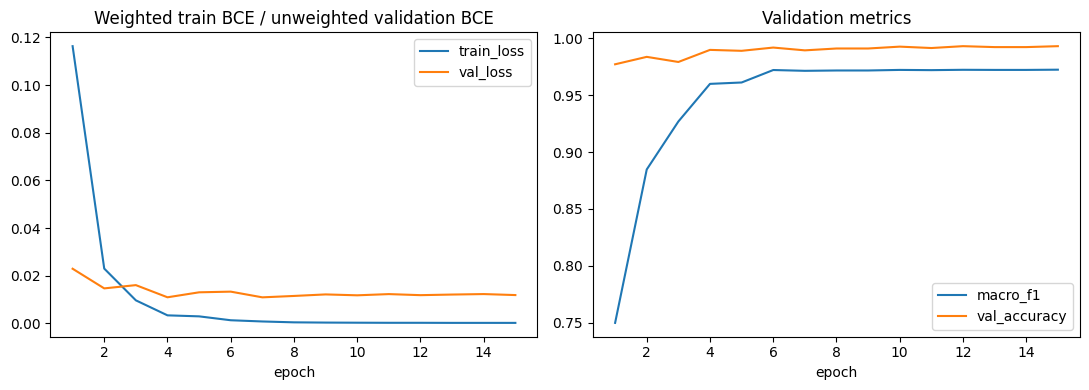

In [14]:
checkpoint = torch.load(BEST_PATH, map_location='cpu', weights_only=True)
assert checkpoint['config']['model_name'] == MODEL_NAME, 'Checkpoint model does not match MODEL_NAME.'
assert checkpoint['config']['label_cols'] == LABEL_COLS
model.load_state_dict(checkpoint['model'])
metrics, per_label, val_probabilities = validate()
val_targets = val_df[LABEL_COLS].to_numpy(dtype=np.int32)
metrics['val_accuracy'] = float(((val_probabilities >= THRESHOLD) == val_targets).all(axis=1).mean())
print('best epoch:', checkpoint['epoch'], '| fixed-0.5 metrics:', metrics)
thresholds = np.asarray(checkpoint['thresholds'], dtype=np.float64)
assert thresholds.shape == (len(LABEL_COLS),) and np.isfinite(thresholds).all()
assert ((thresholds > 0) & (thresholds < 1)).all()
tuned_metrics, tuned_per_label = metric_report(val_targets, val_probabilities, thresholds)
tuned_metrics['val_accuracy'] = float(((val_probabilities >= thresholds) == val_targets).all(axis=1).mean())
print('Validation-fitted thresholds:', dict(zip(LABEL_COLS, thresholds)))
print('Tuned validation metrics (calibration fold):', tuned_metrics)
display(tuned_per_label.assign(threshold=thresholds))
tuned_per_label.assign(threshold=thresholds).to_csv(OUTPUT_DIR / 'validation_metrics_tuned.csv')
display(per_label)
per_label.to_csv(OUTPUT_DIR / 'validation_metrics.csv')

val_predictions = val_df[['image_id', 'cluster', 'fold', *LABEL_COLS]].copy()
for j, label in enumerate(LABEL_COLS):
    val_predictions[f'{label}_prob'] = val_probabilities[:, j]
    val_predictions[f'{label}_pred_0_5'] = (val_probabilities[:, j] >= THRESHOLD).astype(np.int32)
    val_predictions[f'{label}_pred'] = (val_probabilities[:, j] >= thresholds[j]).astype(np.int32)
val_predictions.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)

history_df = pd.DataFrame(history).set_index('epoch')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history_df[['train_loss', 'val_loss']].plot(ax=axes[0], title='Weighted train BCE / unweighted validation BCE')
history_df[['macro_f1', 'val_accuracy']].plot(ax=axes[1], title='Validation metrics')
plt.tight_layout()
plt.show()

## 7. Optional test inference and submission

Reload the best calibrated checkpoint and use the same full-frame evaluation transform.
Apply sigmoid and the checkpoint's per-class thresholds; save probabilities separately.
`submission.csv` contains binary predictions in the competition format and sample row order.
Set `RUN_TEST_INFERENCE = True` to generate it after training/evaluation.
For a new session use `cnn_2_inference.ipynb`, which restores preprocessing and thresholds.

In [15]:
if RUN_TEST_INFERENCE:
    # Reload the best validation checkpoint; this does not retrain the model.
    test_checkpoint = torch.load(BEST_PATH, map_location='cpu', weights_only=True)
    assert test_checkpoint['config']['model_name'] == MODEL_NAME
    assert test_checkpoint['config']['label_cols'] == LABEL_COLS
    assert test_checkpoint['config']['preprocessing'] == preprocessing, 'Rebuild loaders for this checkpoint.'
    test_thresholds = np.asarray(test_checkpoint['thresholds'], dtype=np.float64)
    assert test_thresholds.shape == (len(LABEL_COLS),)
    assert np.isfinite(test_thresholds).all() and ((test_thresholds > 0) & (test_thresholds < 1)).all()
    model.load_state_dict(test_checkpoint['model'])
    print('Test inference with best epoch:', test_checkpoint['epoch'])

    @torch.inference_mode()
    def predict_test():
        model.eval()
        probabilities = []
        for images in tqdm(test_loader, desc='test inference'):
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
            probabilities.append(logits.float().sigmoid().cpu().numpy())
        return np.concatenate(probabilities)

    test_probabilities = predict_test()
    assert test_probabilities.shape == (len(test), len(LABEL_COLS))
    assert np.isfinite(test_probabilities).all()
    assert ((0 <= test_probabilities) & (test_probabilities <= 1)).all()
    probability_frame = pd.DataFrame(test_probabilities, columns=LABEL_COLS)
    probability_frame.insert(0, 'image_id', test.image_id.to_numpy())
    probability_frame.to_csv(OUTPUT_DIR / 'test_probabilities.csv', index=False)

    submission = probability_frame.copy()
    submission[LABEL_COLS] = (test_probabilities >= test_thresholds).astype(np.int32)
    sample_path = DATA_DIR / 'sample_submission.csv'
    if sample_path.is_file():
        sample = pd.read_csv(sample_path, dtype={'image_id': str})
        assert set(sample.columns) == {'image_id', *LABEL_COLS}, 'Check the competition submission schema.'
        assert sample.image_id.notna().all() and sample.image_id.is_unique
        assert set(sample.image_id) == set(test.image_id), 'Sample IDs do not match test IDs.'
        submission = sample[['image_id']].merge(submission, on='image_id', how='left', validate='one_to_one')
    else:
        print('No sample_submission.csv found: using test.csv row order and the documented competition header.')
    submission = submission[['image_id', 'Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']]
    assert len(submission) == len(test) and not submission.isna().any().any()
    assert submission[LABEL_COLS].isin([0, 1]).all().all()
    submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
    print('saved:', OUTPUT_DIR / 'submission.csv')
    from IPython.display import FileLink
    display(FileLink(str(OUTPUT_DIR / 'submission.csv')))
    display(submission.head())
else:
    print('Test inference skipped. Training results are above in Evaluation.')

Test inference skipped. Training results are above in Evaluation.


References: [ImageNet-1k ConvNeXt-Tiny](https://huggingface.co/timm/convnext_tiny.fb_in1k),
[Albumentations affine augmentation](https://albumentations.ai/docs/api-reference/albumentations/augmentations/geometric/transforms/),
[PyTorch BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).
Augmentation and positive-weight recipes adapted from the unchanged `ResNet.ipynb`.